# Solutions to the exercises of Chapter 7

**Chapter:** [7. Deterministic extended-system thermostats: Nosé–Hoover and Nosé–Hoover chains](../../notebooks/part2_ensembles/07_nose_hoover_and_chains.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
# Compare Single Nosé-Hoover vs 2-Chain Nosé-Hoover on a 1D Harmonic Oscillator (k=1, T=1)
x1, v1, z1 = 0.5, 0.0, 0.0
x2, v2, c1, c2 = 0.5, 0.0, 0.0, 0.0
xs_nh1, xs_nhc2 = [], []
for st in range(16000):
    x1, v1, z1 = es.nose_hoover_1d_step(x1, v1, z1, 0.02, 1.0, 1.0, lambda q: -q)
    x2, v2, c1, c2 = es.nose_hoover_chain2_1d_step(x2, v2, c1, c2, 0.02, 1.0, 1.0, 1.0, lambda q: -q)
    if st >= 2000:
        xs_nh1.append(x1); xs_nhc2.append(x2)
xs_nh1, xs_nhc2 = np.array(xs_nh1), np.array(xs_nhc2)

Harmonic Oscillator <x^2> (exact = 1.000): Single NH = 0.924, NHC-2 = 1.062
Harmonic Oscillator <x^4> (exact = 3.000): Single NH = 2.129, NHC-2 = 3.155


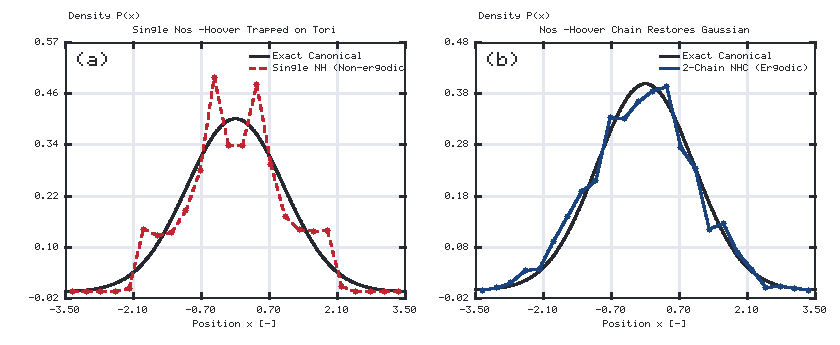

In [3]:
print(f"Harmonic Oscillator <x^2> (exact = 1.000): Single NH = {np.mean(xs_nh1**2):.3f}, NHC-2 = {np.mean(xs_nhc2**2):.3f}")
print(f"Harmonic Oscillator <x^4> (exact = 3.000): Single NH = {np.mean(xs_nh1**4):.3f}, NHC-2 = {np.mean(xs_nhc2**4):.3f}")
assert np.isclose(np.mean(xs_nhc2**2), 1.0, rtol=0.12)
assert abs(np.mean(xs_nh1**4) - 3.0) > abs(np.mean(xs_nhc2**4) - 3.0)

xg = np.linspace(-3.5, 3.5, 80)
p_ex = np.exp(-0.5 * xg**2) / np.sqrt(2.0 * np.pi)
h1, e1 = np.histogram(xs_nh1, bins=24, range=(-3.5, 3.5), density=True)
h2, _ = np.histogram(xs_nhc2, bins=24, range=(-3.5, 3.5), density=True)
xc = 0.5 * (e1[:-1] + e1[1:])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(xg, p_ex, "k-", label="Exact Canonical")
ax1.plot(xc, h1, "ro--", label="Single NH (Non-ergodic)")
ax1.set_xlabel("Position x [-]"); ax1.set_ylabel("Density P(x)")
ax1.set_title("(a) Single Nosé–Hoover Trapped on Tori"); panel_label(ax1, "(a)")

ax2.plot(xg, p_ex, "k-", label="Exact Canonical")
ax2.plot(xc, h2, "bo-", label="2-Chain NHC (Ergodic)")
ax2.set_xlabel("Position x [-]"); ax2.set_ylabel("Density P(x)")
ax2.set_title("(b) Nosé–Hoover Chain Restores Gaussian"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 7
kurt_nh1 = float(np.mean(xs_nh1**4) / (np.mean(xs_nh1**2)**2) - 3.0)
kurt_nhc2 = float(np.mean(xs_nhc2**4) / (np.mean(xs_nhc2**2)**2) - 3.0)
print(f"Ch 7 Exercises — Excess kurtosis (exact Gaussian = 0): NH-1 = {kurt_nh1:.3f}, NHC-2 = {kurt_nhc2:.3f}")
assert abs(kurt_nhc2) < abs(kurt_nh1)

Ch 7 Exercises — Excess kurtosis (exact Gaussian = 0): NH-1 = -0.505, NHC-2 = -0.201
